[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NavaSergio/SP1-material-estudiantes/blob/main/docs/U4-BD/material/01_privacidad_y_datos_sinteticos.ipynb)

# Del dato sensible al dato compartible: seudonimización, enmascaramiento y datos sintéticos

**Seminario de Proyecto I (MCDI) — Unidad 4: Diseño de bases de datos y recolección de información**

La presentación distingue tres técnicas para compartir datos protegiendo la privacidad. Este notebook las pone a prueba sobre **los mismos datos** y, sobre todo, **mide** si funcionan, porque decir "es seguro" sin medirlo no es una afirmación válida.

| Parte | Técnica | Pregunta que respondemos con medidas |
|---|---|---|
| **A** | Seudonimización y enmascaramiento (generalización y supresión) | ¿Qué tan fácil es **reidentificar** a una persona? ¿Cuánta **utilidad** perdemos al protegerla? |
| **B** | Datos sintéticos | ¿Conservan los **patrones** de los datos reales? ¿**Copian** registros reales? |

**Datos.** Usamos el dataset *Adult (Census Income)*, un extracto público del censo de EE. UU. de 1994 con 32,561 personas (variables como edad, sexo, escolaridad, ocupación y si el ingreso supera 50 mil dólares). Como ya es público, **no hay riesgo real**: lo tratamos *como si* fueran datos sensibles de un proyecto. Para ejercitar la seudonimización le agregaremos nombres ficticios, porque este dataset no trae identificadores directos.

**Cómo usarlo.** Funciona en Google Colab o en tu computadora (`pip install -r requirements.txt`). Crea la carpeta `proyecto_privacidad/`.

> **Idea central:** ninguna de estas técnicas "anonimiza" automáticamente. Cada una reduce el riesgo a cambio de algo, y el riesgo que queda **se mide**, no se supone.

In [1]:
import hashlib
import hmac
import io
import subprocess
import sys
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# SDV (Synthetic Data Vault) se usa en la Parte B; en Colab hay que instalarlo.
try:
    import sdv  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sdv"], check=True)

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 140
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAIZ = Path("proyecto_privacidad")
for sub in ["datos/originales", "datos/procesados", "datos/restringido"]:
    (RAIZ / sub).mkdir(parents=True, exist_ok=True)
SEMILLA = 2024
rng = np.random.default_rng(SEMILLA)
print("Carpetas listas en:", RAIZ)

Carpetas listas en: proyecto_privacidad


## Los datos y su procedencia

Descargamos el archivo original una vez y lo guardamos en `datos/originales/` (no se modifica).

- **Fuente:** UCI Machine Learning Repository, *Adult*; creado por B. Becker y R. Kohavi (1996) a partir del censo de 1994 de EE. UU.
- **Licencia:** CC BY 4.0.
- **Valores faltantes:** vienen como `?` en `workclass`, `occupation` y `native-country`.
- **Limitación importante:** es un extracto de **1994 de EE. UU.**; no representa a la población actual ni a otros países, y las categorías (por ejemplo, de raza) son las de ese censo.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
ruta = RAIZ / "datos/originales/adult.data"

if not ruta.exists():
    peticion = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion, timeout=60) as r:
        contenido = r.read()
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        z.extract("adult.data", RAIZ / "datos/originales")
    print("Archivo descargado.")
else:
    print("Se usa el archivo original ya descargado.")

columnas_originales = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
                       "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week",
                       "native_country", "income"]
crudo = pd.read_csv(ruta, names=columnas_originales, skipinitialspace=True, na_values="?")
print("Forma:", crudo.shape)
print("Faltantes por columna:", crudo.isna().sum()[crudo.isna().sum() > 0].to_dict())
crudo.head(3)

Archivo descargado.
Forma: (32561, 15)
Faltantes por columna: {'workclass': 1836, 'occupation': 1843, 'native_country': 583}


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


**Preparación** (todo se documenta): nombres de columnas en español; se eliminan `fnlwgt` (un peso muestral técnico, no una característica de la persona) y `education_num` (redundante con `education`); los valores de las categorías se dejan como en la fuente.

In [3]:
nombres_es = {
    "age": "edad", "workclass": "tipo_empleo", "education": "educacion", "marital_status": "estado_civil",
    "occupation": "ocupacion", "relationship": "relacion_familiar", "race": "raza", "sex": "sexo",
    "capital_gain": "ganancia_capital", "capital_loss": "perdida_capital", "hours_per_week": "horas_semana",
    "native_country": "pais_origen", "income": "ingreso",
}
base = crudo.drop(columns=["fnlwgt", "education_num"]).rename(columns=nombres_es)
base.insert(0, "folio", np.arange(1, len(base) + 1))
print("Variables de trabajo:", base.columns.tolist())

Variables de trabajo: ['folio', 'edad', 'tipo_empleo', 'educacion', 'estado_civil', 'ocupacion', 'relacion_familiar', 'raza', 'sexo', 'ganancia_capital', 'perdida_capital', 'horas_semana', 'pais_origen', 'ingreso']


# Parte A — Seudonimización y enmascaramiento

## A1. Clasificar las variables según su riesgo

Antes de proteger hay que saber **qué** proteger. Las variables se clasifican en:

| Tipo | Qué es | En nuestros datos |
|---|---|---|
| **Identificadores directos** | Identifican a una persona por sí solos (nombre, CURP, correo) | No trae; **agregaremos `nombre` ficticio** |
| **Cuasi-identificadores** | Aisladamente no identifican, **combinados sí** (edad, sexo, ciudad, escolaridad...) | `edad`, `sexo`, `raza`, `estado_civil`, `pais_origen`, `educacion` |
| **Atributo sensible** | Lo que no queremos que se revele de nadie | `ingreso` |
| **Otras variables** | Resto de la información | `tipo_empleo`, `ocupacion`, `horas_semana`, ... |

Creamos nombres ficticios (nombre y dos apellidos, generados al azar) solo para ilustrar:

In [4]:
nombres = ["Ana", "Luis", "María", "Carlos", "Sofía", "Jorge", "Lucía", "Pedro", "Elena", "Raúl", "Paula", "Diego",
           "Rosa", "Andrés", "Marta", "Hugo", "Clara", "Iván", "Julia", "Mario", "Irene", "Pablo", "Nora", "Óscar",
           "Laura", "Sergio", "Carla", "Tomás", "Alma", "Víctor", "Inés", "Felipe", "Gloria", "Ramón", "Silvia",
           "Daniel", "Teresa", "Bruno", "Olga", "Emilio", "Diana", "Rubén", "Ximena", "Enrique", "Beatriz",
           "Gael", "Renata", "Ismael", "Valeria", "Adrián"]
apellidos = ["García", "López", "Martínez", "Pérez", "Sánchez", "Ramírez", "Torres", "Flores", "Rivera", "Gómez",
             "Díaz", "Reyes", "Cruz", "Morales", "Ortiz", "Gutiérrez", "Chávez", "Ramos", "Mendoza", "Ruiz",
             "Álvarez", "Castillo", "Jiménez", "Vargas", "Romero", "Herrera", "Medina", "Aguilar", "Guerrero", "Núñez",
             "Rojas", "Soto", "Delgado", "Vega", "Salazar", "Campos", "Fuentes", "Navarro", "Ibarra", "Lara",
             "Cortés", "Mora", "Silva", "Peña", "Ríos", "Cabrera", "Santos", "Zamora", "Orozco", "Pacheco"]

def nombre_ficticio():
    return f"{rng.choice(nombres)} {rng.choice(apellidos)} {rng.choice(apellidos)}"

personas = base.copy()
personas.insert(1, "nombre", [nombre_ficticio() for _ in range(len(personas))])
personas[["folio", "nombre", "edad", "sexo", "pais_origen", "ingreso"]].head()

,folio,nombre,edad,sexo,pais_origen,ingreso
0,1,Rosa Vega Sánchez,39,Male,United-States,<=50K
1,2,Paula Gutiérrez Gutiérrez,50,Male,United-States,<=50K
2,3,Gael Lara Cabrera,38,Male,United-States,<=50K
3,4,Adrián Pérez Flores,53,Male,United-States,<=50K
4,5,Enrique Pérez Rivera,28,Female,Cuba,<=50K


## A2. Seudonimización: sustituir identificadores directos por códigos

Seudonimizar es reemplazar el identificador directo por un código y **guardar la tabla de equivalencias por separado**. Pero **cómo** se genera el código importa mucho. Un error común es usar una función *hash* (por ejemplo, SHA-256) del nombre directamente. Veamos por qué falla:

In [5]:
def hash_simple(texto):
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()[:12]

# Código "seudónimo" construido con un hash simple del nombre
personas["codigo_hash_simple"] = personas["nombre"].map(hash_simple)

# Ataque: quien conozca el formato de los nombres puede generar TODAS las combinaciones posibles
inicio = time.time()
diccionario_ataque = {
    hash_simple(f"{n} {a1} {a2}"): f"{n} {a1} {a2}"
    for n in nombres for a1 in apellidos for a2 in apellidos
}
recuperados = personas["codigo_hash_simple"].map(diccionario_ataque)
print(f"Combinaciones de nombre generadas por el atacante: {len(diccionario_ataque):,} "
      f"({time.time() - inicio:.1f} s)")
print(f"Nombres recuperados a partir de los códigos: {(recuperados == personas['nombre']).mean():.0%}")

Combinaciones de nombre generadas por el atacante: 125,000 (0.2 s)
Nombres recuperados a partir de los códigos: 100%


El hash simple **no protege**: los nombres tienen un espacio de posibilidades pequeño y el atacante puede probarlos todos. La alternativa es usar una **clave secreta** (HMAC), que el atacante no tiene:

In [6]:
CLAVE_SECRETA = b"clave-de-ejemplo-no-usar-en-proyectos-reales"   # en un proyecto real: se guarda aparte y NUNCA en el repositorio

def seudonimo(texto, clave=CLAVE_SECRETA):
    return hmac.new(clave, texto.encode("utf-8"), hashlib.sha256).hexdigest()[:12]

personas["id_seudonimo"] = personas["nombre"].map(seudonimo)

# El mismo ataque ya no funciona sin la clave
recuperados_hmac = personas["id_seudonimo"].map(diccionario_ataque)
print(f"Nombres recuperados con el mismo ataque: {recuperados_hmac.notna().mean():.0%}")

# La tabla de equivalencias (código <-> nombre) se guarda SEPARADA y con acceso restringido
personas[["id_seudonimo", "folio", "nombre"]].to_csv(RAIZ / "datos/restringido/equivalencias.csv", index=False)

# La tabla "para compartir" ya no contiene el nombre
seudonimizada = personas.drop(columns=["nombre", "folio", "codigo_hash_simple"])
seudonimizada.insert(0, "id_seudonimo", seudonimizada.pop("id_seudonimo"))
seudonimizada.head(3)

Nombres recuperados con el mismo ataque: 0%


,id_seudonimo,edad,tipo_empleo,educacion,estado_civil,ocupacion,relacion_familiar,raza,sexo,ganancia_capital,perdida_capital,horas_semana,pais_origen,ingreso
0,e5ad623216a4,39,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,78ebc1c4dabf,50,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,f598b8d0de06,38,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


Con la clave secreta el ataque falla. Pero **seudonimizar no es anonimizar**: aunque quitamos el nombre, quedan los cuasi-identificadores. Si alguien sabe la edad, el sexo, la raza y el país de origen de una persona (por ejemplo, de sus redes sociales), puede intentar encontrarla en la tabla "protegida".

## A3. Medir el riesgo: k-anonimato

Una tabla cumple **k-anonimato** (Sweeney, 2002) si cada combinación de cuasi-identificadores aparece **al menos k veces**: así, cada persona se "confunde" con otras k − 1. Si una combinación aparece **una sola vez** (k = 1), esa persona es única y se puede reidentificar. Medimos:

In [7]:
QI = ["sexo", "raza", "edad", "pais_origen", "estado_civil", "educacion"]

def tamano_clase(d, qi):
    # Para cada fila, cuántas filas comparten exactamente sus cuasi-identificadores
    return d.groupby(qi, dropna=False)[qi[0]].transform("size")

def resumen_k(d, qi):
    k = tamano_clase(d, qi)
    return pd.Series({
        "combinaciones distintas": d.groupby(qi, dropna=False).ngroups,
        "k mínimo": int(k.min()),
        "% de personas únicas (k = 1)": 100 * (k == 1).mean(),
        "% con k < 5": 100 * (k < 5).mean(),
    })

# ¿Cómo crece el riesgo al conocer más atributos?
filas = []
for n in range(2, len(QI) + 1):
    r = resumen_k(seudonimizada, QI[:n])
    r.name = f"{n} atributos (hasta {QI[n - 1]})"
    filas.append(r)
riesgo_progresivo = pd.DataFrame(filas).astype({"combinaciones distintas": int, "k mínimo": int})
riesgo_progresivo

,combinaciones distintas,k mínimo,% de personas únicas (k = 1),% con k < 5
2 atributos (hasta raza),10,109,0.00,0.00
3 atributos (hasta edad),546,1,0.20,1.30
4 atributos (hasta pais_origen),2382,1,4.08,9.32
5 atributos (hasta estado_civil),3900,1,7.25,13.93
6 atributos (hasta educacion),8553,1,17.18,31.14


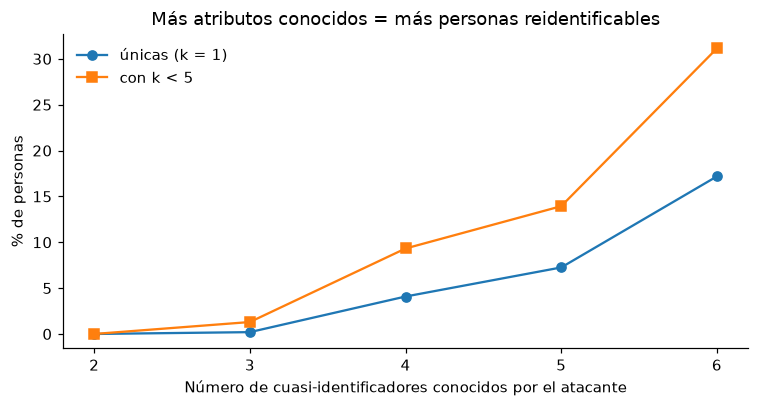

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(2, len(QI) + 1), riesgo_progresivo["% de personas únicas (k = 1)"], marker="o", label="únicas (k = 1)")
ax.plot(range(2, len(QI) + 1), riesgo_progresivo["% con k < 5"], marker="s", label="con k < 5")
ax.set_xticks(range(2, len(QI) + 1))
ax.set_xlabel("Número de cuasi-identificadores conocidos por el atacante")
ax.set_ylabel("% de personas")
ax.set_title("Más atributos conocidos = más personas reidentificables")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Cuantos más atributos "inocentes" combina un atacante, más personas quedan **únicas**. Nadie es identificable por su sexo o su raza por separado; pero la **combinación** sí identifica. Este fenómeno está bien documentado: Rocher et al. (2019) estimaron que, con 15 atributos demográficos, se podría reidentificar correctamente al 99.98% de la población de EE. UU. incluso en bases incompletas.

Además de saber *quién* es, el atacante puede aprender el **atributo sensible**. Si todas las personas de un grupo comparten el mismo ingreso, basta ubicar a alguien en ese grupo para conocer su ingreso, aunque el grupo sea grande (esto se conoce como *revelación del atributo*, y es la razón por la que existe la idea de *l-diversidad*). Lo medimos más adelante.

## A4. Enmascaramiento: generalizar y suprimir

Para reducir el riesgo **degradamos deliberadamente** los cuasi-identificadores:

- **Generalización:** reemplazar un valor por una categoría más amplia (edad exacta → rango de edad; país → "Estados Unidos / Otro").
- **Supresión:** eliminar los registros que, aun después de generalizar, siguen siendo demasiado únicos.

In [9]:
nivel_educ = {
    "Preschool": "Sin bachillerato", "1st-4th": "Sin bachillerato", "5th-6th": "Sin bachillerato",
    "7th-8th": "Sin bachillerato", "9th": "Sin bachillerato", "10th": "Sin bachillerato",
    "11th": "Sin bachillerato", "12th": "Sin bachillerato", "HS-grad": "Bachillerato",
    "Some-college": "Universidad sin título", "Assoc-voc": "Técnico/asociado", "Assoc-acdm": "Técnico/asociado",
    "Bachelors": "Licenciatura", "Masters": "Posgrado", "Prof-school": "Posgrado", "Doctorate": "Posgrado",
}
grupo_civil = {
    "Married-civ-spouse": "Casado/a", "Married-AF-spouse": "Casado/a", "Married-spouse-absent": "Casado/a",
    "Never-married": "Soltero/a", "Divorced": "Divorciado/separado/viudo", "Separated": "Divorciado/separado/viudo",
    "Widowed": "Divorciado/separado/viudo",
}

def generalizar(d):
    g = d.copy()
    g["edad"] = pd.cut(d["edad"], [0, 25, 35, 45, 55, 65, 120],
                       labels=["<=25", "26-35", "36-45", "46-55", "56-65", ">65"]).astype(str)
    g["pais_origen"] = np.where(d["pais_origen"].isna(), "Desconocido",
                                np.where(d["pais_origen"] == "United-States", "Estados Unidos", "Otro"))
    g["educacion"] = d["educacion"].map(nivel_educ)
    g["estado_civil"] = d["estado_civil"].map(grupo_civil)
    g["raza"] = d["raza"].where(d["raza"].isin(["White", "Black", "Asian-Pac-Islander"]), "Otra")
    return g

generalizada = generalizar(seudonimizada)
K_OBJETIVO = 5

k = tamano_clase(generalizada, QI)
print(f"Tras generalizar: {100 * (k == 1).mean():.2f}% únicas y {100 * (k < K_OBJETIVO).mean():.2f}% con k < {K_OBJETIVO}")

# Supresión: eliminamos las filas cuyo grupo sigue siendo menor a k
enmascarada = generalizada[k >= K_OBJETIVO].copy()
print(f"Filas suprimidas: {len(generalizada) - len(enmascarada)} de {len(generalizada)} "
      f"({100 * (1 - len(enmascarada) / len(generalizada)):.2f}%)")
print(f"k mínimo en la tabla final: {tamano_clase(enmascarada, QI).min()}")

Tras generalizar: 1.13% únicas y 4.16% con k < 5
Filas suprimidas: 1353 de 32561 (4.16%)
k mínimo en la tabla final: 5


### ¿Cuánto cuesta proteger? Medir la pérdida de utilidad

Proteger tiene un costo, pero **hay que medirlo**, no suponerlo. Medimos la **utilidad** con una tarea concreta: predecir si el ingreso supera los 50 mil dólares con una regresión logística, comparando la tabla original con la enmascarada **sobre las mismas personas** (mismo reparto de entrenamiento y prueba). La métrica es el AUC (1 = perfecto, 0.5 = azar).

In [10]:
def auc_de_modelo(d, indices_entrenamiento, indices_prueba):
    y = (d["ingreso"] == ">50K").astype(int)
    X = d.drop(columns=["ingreso", "id_seudonimo"])
    numericas = X.select_dtypes("number").columns.tolist()
    categoricas = [c for c in X.columns if c not in numericas]
    X = X.copy()
    X[categoricas] = X[categoricas].fillna("Desconocido")
    pre = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])
    modelo = make_pipeline(pre, LogisticRegression(max_iter=1000))
    modelo.fit(X.loc[indices_entrenamiento], y.loc[indices_entrenamiento])
    return roc_auc_score(y.loc[indices_prueba], modelo.predict_proba(X.loc[indices_prueba])[:, 1])

indices = enmascarada.index
entrena_idx, prueba_idx = train_test_split(indices, test_size=0.3, random_state=SEMILLA)

auc_original = auc_de_modelo(seudonimizada, entrena_idx, prueba_idx)
auc_enmascarada = auc_de_modelo(enmascarada, entrena_idx, prueba_idx)
print(f"AUC con los datos originales (seudonimizados):  {auc_original:.3f}")
print(f"AUC con los datos enmascarados:                  {auc_enmascarada:.3f}")
print(f"Pérdida de utilidad: {auc_original - auc_enmascarada:.3f}")

AUC con los datos originales (seudonimizados):  0.906
AUC con los datos enmascarados:                  0.909
Pérdida de utilidad: -0.003


Para **esta tarea**, la utilidad prácticamente no cambió (la diferencia está dentro del ruido). Eso **no significa** que enmascarar sea gratis: la utilidad se mide **para la tarea que importa**. Si la pregunta de tu proyecto exigiera la edad exacta, o analizar grupos pequeños, la pérdida sería otra.

Y hay un costo que el AUC no ve: las filas que suprimimos **no son una muestra al azar**. Son, por construcción, las personas con perfiles **poco comunes**. Comparemos quiénes se quedaron y quiénes salieron:

In [11]:
suprimidas = generalizada[k < K_OBJETIVO]
comparacion_supresion = pd.DataFrame({
    "% en la tabla enmascarada": [100 * (enmascarada["pais_origen"] == "Otro").mean(),
                                  100 * (enmascarada["raza"] == "Otra").mean(),
                                  100 * (enmascarada["raza"] == "Asian-Pac-Islander").mean()],
    "% entre las filas suprimidas": [100 * (suprimidas["pais_origen"] == "Otro").mean(),
                                     100 * (suprimidas["raza"] == "Otra").mean(),
                                     100 * (suprimidas["raza"] == "Asian-Pac-Islander").mean()],
}, index=["Nacidos fuera de EE. UU.", "Raza 'Otra'", "Raza 'Asian-Pac-Islander'"])
comparacion_supresion

,% en la tabla enmascarada,% entre las filas suprimidas
Nacidos fuera de EE. UU.,7.16,42.35
Raza 'Otra',0.90,22.25
Raza 'Asian-Pac-Islander',2.20,25.94


La supresión **elimina de forma desproporcionada** a quienes pertenecen a grupos poco frecuentes. Si tu proyecto estudia justamente a esos grupos, suprimir sus registros puede borrar el objeto de estudio y **sesgar** las conclusiones. Es el mismo problema de fondo que aparece al excluir países sin dato en el ejemplo del Banco Mundial: quien queda fuera no es aleatorio.

### El atributo sensible: k-anonimato no basta

Aunque cada grupo tenga al menos 5 personas, si **todas** tienen el mismo ingreso, el atacante aprende el ingreso de cualquiera de ellas sin necesidad de distinguirla:

In [12]:
def pct_homogeneo(d, qi, sensible="ingreso"):
    valores_distintos = d.groupby(qi, dropna=False)[sensible].transform("nunique")
    return 100 * (valores_distintos == 1).mean()

print(f"Tabla seudonimizada (sin enmascarar): {pct_homogeneo(seudonimizada, QI):.1f}% de las personas están en un grupo "
      f"donde todos tienen el mismo ingreso")
print(f"Tabla enmascarada (k >= {K_OBJETIVO}):               {pct_homogeneo(enmascarada, QI):.1f}% de las personas están en un grupo "
      f"donde todos tienen el mismo ingreso")

Tabla seudonimizada (sin enmascarar): 49.2% de las personas están en un grupo donde todos tienen el mismo ingreso
Tabla enmascarada (k >= 5):               16.3% de las personas están en un grupo donde todos tienen el mismo ingreso


Aun con k ≥ 5, una parte de las personas está en un grupo **homogéneo** en el atributo sensible: para ellas, el enmascaramiento no protegió el ingreso. Hay refinamientos (*l-diversidad*, generalizar más, suprimir esos grupos), cada uno con más costo en utilidad. Lo importante es la conclusión metodológica: **medir el riesgo con más de un criterio**.

## A5. Resumen de la Parte A

In [13]:
def fila_resumen(nombre, d, auc):
    # Riesgo medido sobre la tabla indicada; el AUC siempre se calcula con las mismas personas (ver arriba)
    k = tamano_clase(d, QI)
    return {
        "Versión": nombre,
        "Filas": len(d),
        "k mínimo": int(k.min()),
        "% únicas (k = 1)": 100 * (k == 1).mean(),
        "% con k < 5": 100 * (k < 5).mean(),
        "% en grupos homogéneos (ingreso)": pct_homogeneo(d, QI),
        "AUC (utilidad)": auc,
    }

resumen_a = pd.DataFrame([
    fila_resumen("Seudonimizada (solo se quitó el nombre)", seudonimizada, auc_original),
    fila_resumen("Enmascarada (generalizada + suprimida)", enmascarada, auc_enmascarada),
]).set_index("Versión")
resumen_a

,Filas,k mínimo,% únicas (k = 1),% con k < 5,% en grupos homogéneos (ingreso),AUC (utilidad)
Versión,,,,,,
Seudonimizada (solo se quitó el nombre),32561,1,17.18,31.14,49.18,0.91
Enmascarada (generalizada + suprimida),31208,5,0.00,0.00,16.29,0.91


In [14]:
enmascarada.to_csv(RAIZ / "datos/procesados/adultos_enmascarados.csv", index=False)
print("Guardada:", RAIZ / "datos/procesados/adultos_enmascarados.csv")

Guardada: proyecto_privacidad/datos/procesados/adultos_enmascarados.csv


**Lo aprendido en la Parte A**

1. Quitar el nombre (o cambiarlo por un código) **no basta**: los cuasi-identificadores combinados reidentifican.
2. Un hash simple del nombre se invierte probando posibilidades; se necesita una **clave secreta** guardada aparte.
3. Generalizar y suprimir reduce el riesgo de forma **medible**, a cambio de **detalle** (y se puede medir cuánto).
4. El k-anonimato no protege el atributo sensible por sí solo.
5. Ninguna de estas técnicas ofrece una **garantía formal**: reducen el riesgo, no lo eliminan.

---

# Parte B — Datos sintéticos

Un generador sintético **aprende** los patrones estadísticos de los datos reales y produce **filas nuevas**. En teoría ninguna fila corresponde a una persona real, pero eso hay que **verificarlo**. Evaluamos dos cosas con medidas:

- **Utilidad:** ¿se conservan las distribuciones y las **relaciones** entre variables?
- **Privacidad:** ¿el generador **copia** registros reales?

## B1. Preparación: entrenamiento y reserva

Para evaluar con honestidad separamos **los datos reales en dos**: 70% para *entrenar* el generador y 30% de **reserva** que el generador **nunca ve**. La reserva sirve de punto de comparación (ya veremos para qué).

In [15]:
variables_b = ["edad", "tipo_empleo", "educacion", "estado_civil", "ocupacion", "relacion_familiar", "raza", "sexo",
               "ganancia_capital", "perdida_capital", "horas_semana", "pais_origen", "ingreso"]
real = base[variables_b].copy()
# Los faltantes de las categóricas se registran como una categoría explícita (decisión documentada)
categoricas_b = [c for c in variables_b if real[c].dtype == object or str(real[c].dtype) in ("str", "string")]
real[categoricas_b] = real[categoricas_b].fillna("Desconocido")

entrenamiento, reserva = train_test_split(real, test_size=0.3, random_state=SEMILLA)
entrenamiento = entrenamiento.reset_index(drop=True)
reserva = reserva.reset_index(drop=True)
print(f"Entrenamiento: {len(entrenamiento):,} filas | Reserva: {len(reserva):,} filas")

Entrenamiento: 22,792 filas | Reserva: 9,769 filas


## B2. Dos generadores para comparar

1. **Línea base ingenua:** muestrear cada columna **por separado** de los datos reales. Conserva cada distribución individual, pero **rompe las relaciones** entre variables (ejemplo: la edad deja de relacionarse con el estado civil).
2. **SDV** (*Synthetic Data Vault*, Patki et al., 2016) con `GaussianCopulaSynthesizer`: aprende cada distribución **y** la dependencia entre variables.

> **Licencia de SDV:** usa la licencia *Business Source License 1.1*, que no es de código abierto: permite el uso no productivo (investigación, docencia) y prohíbe ofrecer con él un servicio comercial de datos sintéticos. Para este curso no hay problema; para otros usos conviene revisarla.

Y un **control negativo**: una "copia" que simplemente remuestrea filas reales. No es sintética; sirve para comprobar que nuestras medidas de privacidad **detectan** el copiado.

In [16]:
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer

N = len(entrenamiento)

# 1) Línea base ingenua
sintetico_ingenuo = pd.DataFrame({
    c: rng.choice(entrenamiento[c].to_numpy(), size=N, replace=True) for c in entrenamiento.columns
})

# 2) SDV: Gaussian copula
np.random.seed(SEMILLA)
metadatos = Metadata.detect_from_dataframe(data=entrenamiento, table_name="adultos")
sintetizador = GaussianCopulaSynthesizer(metadatos)
inicio = time.time()
sintetizador.fit(entrenamiento)
sintetico_sdv = sintetizador.sample(num_rows=N)
print(f"SDV entrenado y muestreado en {time.time() - inicio:.1f} s")

# 3) Control negativo: remuestreo de filas reales (NO es sintético)
copia_control = entrenamiento.sample(n=N, replace=True, random_state=SEMILLA).reset_index(drop=True)

sintetico_sdv.head()

SDV entrenado y muestreado en 5.1 s


,edad,tipo_empleo,educacion,estado_civil,ocupacion,relacion_familiar,raza,sexo,ganancia_capital,perdida_capital,horas_semana,pais_origen,ingreso
0,48,Private,HS-grad,Married-civ-spouse,Exec-managerial,Husband,White,Female,53948,0,53,United-States,<=50K
1,54,Private,HS-grad,Divorced,Exec-managerial,Not-in-family,White,Male,78369,0,33,United-States,<=50K
2,36,State-gov,Bachelors,Married-spouse-absent,Sales,Wife,White,Male,78016,1,32,United-States,<=50K
3,52,Self-emp-not-inc,Some-college,Never-married,Craft-repair,Husband,Asian-Pac-Islander,Male,9474,25,39,United-States,<=50K
4,58,Private,HS-grad,Married-civ-spouse,Exec-managerial,Not-in-family,White,Male,1520,10,19,United-States,<=50K


## B3. Utilidad (1): ¿se parecen las distribuciones y las relaciones?

SDV incluye una medida de calidad que compara cada columna (*Column Shapes*) y cada par de columnas (*Column Pair Trends*), con un puntaje de 0 a 1. Para **interpretar** esos puntajes necesitamos una referencia: ¿qué puntaje obtiene la **reserva real** frente al entrenamiento? Ese es el "techo" realista (incluso datos reales distintos difieren por azar).

In [17]:
from sdv.evaluation.single_table import evaluate_quality

def calidad(sintetico, nombre):
    reporte = evaluate_quality(real_data=entrenamiento, synthetic_data=sintetico, metadata=metadatos, verbose=False)
    propiedades = reporte.get_properties().set_index("Property")["Score"]
    return {
        "Datos evaluados": nombre,
        "Puntaje global": reporte.get_score(),
        "Distribuciones (Column Shapes)": propiedades["Column Shapes"],
        "Relaciones entre pares (Pair Trends)": propiedades["Column Pair Trends"],
    }

resultados_calidad = pd.DataFrame([
    calidad(reserva.iloc[:N], "Reserva real (techo de referencia)"),
    calidad(sintetico_sdv, "Sintéticos con SDV"),
    calidad(sintetico_ingenuo, "Línea base ingenua"),
]).set_index("Datos evaluados")
resultados_calidad

,Puntaje global,Distribuciones (Column Shapes),Relaciones entre pares (Pair Trends)
Datos evaluados,,,
Reserva real (techo de referencia),0.99,0.99,0.98
Sintéticos con SDV,0.86,0.88,0.85
Línea base ingenua,0.90,1.00,0.80


**Cómo leer la tabla.** La línea base ingenua obtiene un puntaje perfecto en **distribuciones** (copió cada columna), pero un puntaje menor en **relaciones entre pares**. SDV hace lo contrario: sacrifica algo de ajuste en cada columna a cambio de modelar las dependencias.

Fíjate en algo importante: el **puntaje global de la línea base ingenua es mayor** que el de SDV, aunque ya sabemos que ignora las relaciones. **Una métrica agregada puede engañar**; por eso no basta con un solo número y hay que mirar la utilidad para el **uso** que le darás a los datos (siguientes secciones).

Veámoslo en gráficas: dos distribuciones y, sobre todo, una **relación** (la proporción de personas con ingreso alto según su escolaridad).

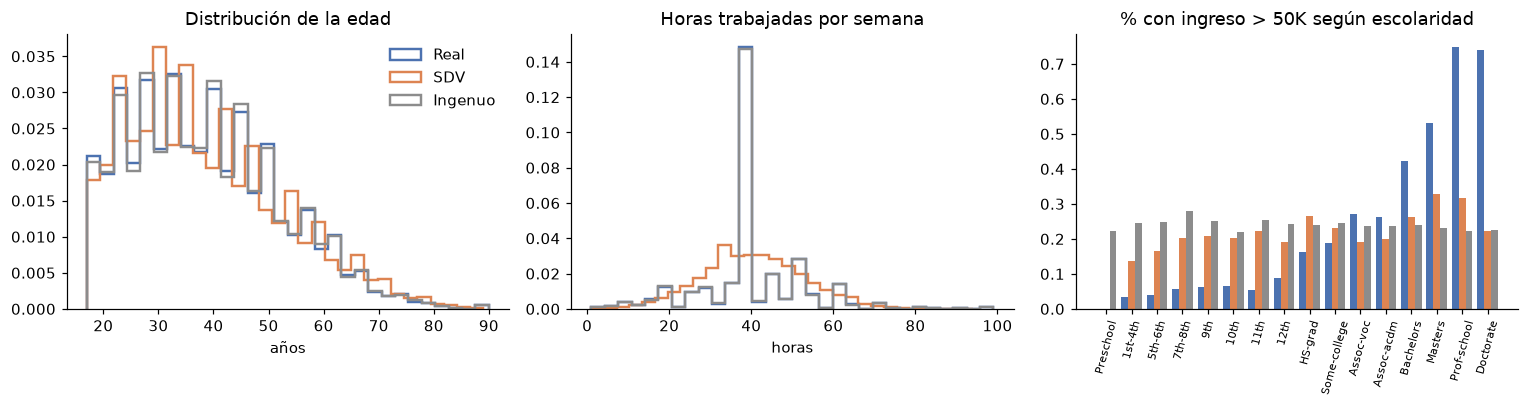

In [18]:
orden_educ = ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th", "HS-grad",
              "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters", "Prof-school", "Doctorate"]
colores = {"Real": "#4c72b0", "SDV": "#dd8452", "Ingenuo": "#8c8c8c"}
series = {"Real": entrenamiento, "SDV": sintetico_sdv, "Ingenuo": sintetico_ingenuo}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

for nombre, d in series.items():
    axes[0].hist(d["edad"], bins=30, density=True, histtype="step", lw=1.6, label=nombre, color=colores[nombre])
    axes[1].hist(d["horas_semana"], bins=30, density=True, histtype="step", lw=1.6, label=nombre, color=colores[nombre])
axes[0].set_title("Distribución de la edad"); axes[0].set_xlabel("años")
axes[1].set_title("Horas trabajadas por semana"); axes[1].set_xlabel("horas")
axes[0].legend(frameon=False)

ancho = 0.27
for j, (nombre, d) in enumerate(series.items()):
    tasa = (d.assign(alto=(d["ingreso"] == ">50K")).groupby("educacion")["alto"].mean().reindex(orden_educ))
    axes[2].bar(np.arange(len(orden_educ)) + (j - 1) * ancho, tasa.fillna(0), width=ancho, color=colores[nombre], label=nombre)
axes[2].set_xticks(np.arange(len(orden_educ)))
axes[2].set_xticklabels(orden_educ, rotation=75, fontsize=7)
axes[2].set_title("% con ingreso > 50K según escolaridad")
plt.tight_layout()
plt.show()

La línea base ingenua reproduce las distribuciones individuales, pero la tercera gráfica muestra que **destruye la relación** entre escolaridad e ingreso (todas las barras grises miden casi lo mismo). SDV conserva la **dirección** de la relación (el ingreso alto es más frecuente a mayor escolaridad), pero la **atenúa mucho**: por ejemplo, en los datos reales cerca de tres de cada cuatro personas con posgrado profesional tienen ingreso alto, y en los sintéticos solo cerca de una de cada tres. Además, en la segunda gráfica SDV **suaviza el pico de las 40 horas semanales**, que en los datos reales es muy marcado. Una base sintética que pierde las relaciones es inútil para el análisis; una que las debilita sirve para otras cosas (por ejemplo, probar código), pero **no** para estimar efectos.

### Un límite que esas gráficas no muestran: las variables con muchos ceros

Mira dos variables del dataset: la **ganancia** y la **pérdida de capital**. En los datos reales casi todas las personas tienen **cero**, y solo unas pocas tienen valores grandes. Un generador que modela variables como si fueran continuas suaves tiene dificultad con ese "pico en cero":

In [19]:
comparacion_ceros = pd.DataFrame({
    nombre: {
        "% de ceros en ganancia_capital": 100 * (d["ganancia_capital"] == 0).mean(),
        "% de ceros en perdida_capital": 100 * (d["perdida_capital"] == 0).mean(),
        "ganancia_capital promedio": d["ganancia_capital"].mean(),
        "ganancia_capital máxima": d["ganancia_capital"].max(),
    }
    for nombre, d in series.items()
}).T
comparacion_ceros

,% de ceros en ganancia_capital,% de ceros en perdida_capital,ganancia_capital promedio,ganancia_capital máxima
Real,91.72,95.27,1113.72,99999.00
SDV,2.37,55.85,28848.83,99999.00
Ingenuo,91.75,95.37,998.76,99999.00


Los sintéticos de SDV tienen **muchas menos personas con cero** y valores de ganancia **enormes** (el promedio de ganancia de capital es mucho mayor que en los datos reales). Es decir: el generador produce "personas" con una ganancia de capital que casi nadie tiene. La métrica global no lo reveló. Para variables así hay que **revisar caso por caso** (y existen generadores o restricciones más adecuados). Por esto, un sintético **nunca** se acepta solo por su puntaje: se revisan las variables que importan para tu pregunta.

## B4. Utilidad (2): entrenar con sintéticos, probar con datos reales

Una medida práctica de utilidad (*TSTR*: *train on synthetic, test on real*): entrenamos el modelo que predice el ingreso con los datos sintéticos y lo **evaluamos con la reserva real**. Si los sintéticos conservan lo importante, el AUC debe acercarse al de un modelo entrenado con datos reales.

In [20]:
def auc_tstr(datos_entrenamiento, datos_prueba):
    y_tr = (datos_entrenamiento["ingreso"] == ">50K").astype(int)
    y_te = (datos_prueba["ingreso"] == ">50K").astype(int)
    X_tr, X_te = datos_entrenamiento.drop(columns="ingreso"), datos_prueba.drop(columns="ingreso")
    numericas = X_tr.select_dtypes("number").columns.tolist()
    categoricas = [c for c in X_tr.columns if c not in numericas]
    pre = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])
    modelo = make_pipeline(pre, LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
    return roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1])

tstr = pd.DataFrame({
    "AUC en la reserva real": {
        "Entrenado con datos reales (referencia)": auc_tstr(entrenamiento, reserva),
        "Entrenado con sintéticos SDV": auc_tstr(sintetico_sdv, reserva),
        "Entrenado con la línea base ingenua": auc_tstr(sintetico_ingenuo, reserva),
    }
})
tstr

,AUC en la reserva real
Entrenado con datos reales (referencia),0.91
Entrenado con sintéticos SDV,0.84
Entrenado con la línea base ingenua,0.53


Si el modelo entrenado con SDV se acerca a la referencia y el ingenuo cae hacia el azar (0.5), la utilidad está respaldada por una medida de **uso**, no solo por gráficas.

## B5. Privacidad: ¿el generador copia registros reales?

Aquí hay un error de interpretación frecuente: encontrar filas sintéticas **idénticas** a filas reales **no prueba por sí solo** que se copió, porque en datos con pocas variables dos personas distintas pueden coincidir por casualidad. La pregunta correcta es: **¿coincide más de lo que coincidirían datos reales que el generador nunca vio?** Por eso existe la **reserva**: sirve de punto de comparación.

Dos medidas:

1. **Copias exactas:** % de filas que coinciden **exactamente** con alguna fila del entrenamiento.
2. **Distancia al registro más cercano (DCR):** para cada fila, la distancia a la fila real más parecida del entrenamiento. Si el generador copia, esa distancia es ~0 para muchas filas.

In [21]:
def hashes_de_filas(d):
    return pd.util.hash_pandas_object(d, index=False).to_numpy()

hashes_entrenamiento = hashes_de_filas(entrenamiento)

def pct_copias_exactas(d):
    return 100 * np.isin(hashes_de_filas(d), hashes_entrenamiento).mean()

# Representación numérica para medir distancias (categóricas en 0/1, numéricas estandarizadas)
categoricas_dcr = [c for c in entrenamiento.columns if c not in ["edad", "ganancia_capital", "perdida_capital", "horas_semana"]]
numericas_dcr = ["edad", "ganancia_capital", "perdida_capital", "horas_semana"]
codificador = ColumnTransformer([
    ("num", StandardScaler(), numericas_dcr),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas_dcr),
]).fit(entrenamiento)
vecino = NearestNeighbors(n_neighbors=1).fit(codificador.transform(entrenamiento))

def dcr(d, n=3000):
    muestra = d.sample(n=min(n, len(d)), random_state=SEMILLA)
    distancias, _ = vecino.kneighbors(codificador.transform(muestra))
    return distancias.ravel()

candidatos = {
    "Reserva real (referencia: nunca vista)": reserva,
    "Sintéticos con SDV": sintetico_sdv,
    "Línea base ingenua": sintetico_ingenuo,
    "Control negativo (copia de filas reales)": copia_control,
}
filas = []
dcr_por_grupo = {}
for nombre, d in candidatos.items():
    distancias = dcr(d)
    dcr_por_grupo[nombre] = distancias
    filas.append({
        "Datos evaluados": nombre,
        "% copias exactas": pct_copias_exactas(d),
        "DCR mediana": np.median(distancias),
        "DCR percentil 5": np.percentile(distancias, 5),
    })
privacidad = pd.DataFrame(filas).set_index("Datos evaluados")
privacidad

,% copias exactas,DCR mediana,DCR percentil 5
Datos evaluados,,,
Reserva real (referencia: nunca vista),14.20,0.50,0.00
Sintéticos con SDV,0.00,2.31,0.77
Línea base ingenua,1.29,1.67,0.29
Control negativo (copia de filas reales),100.00,0.00,0.00


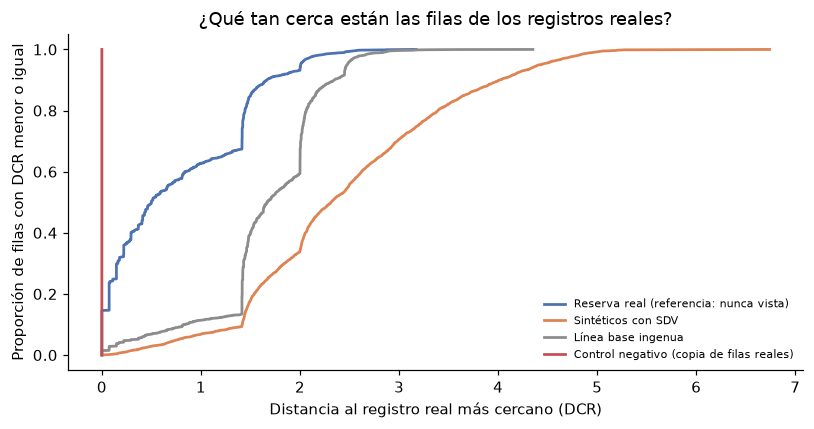

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 4))
estilos = {"Reserva real (referencia: nunca vista)": "#4c72b0", "Sintéticos con SDV": "#dd8452",
           "Línea base ingenua": "#8c8c8c", "Control negativo (copia de filas reales)": "#c44e52"}
for nombre, distancias in dcr_por_grupo.items():
    ordenadas = np.sort(distancias)
    ax.plot(ordenadas, np.arange(1, len(ordenadas) + 1) / len(ordenadas), lw=1.8, color=estilos[nombre], label=nombre)
ax.set_xlabel("Distancia al registro real más cercano (DCR)")
ax.set_ylabel("Proporción de filas con DCR menor o igual")
ax.set_title("¿Qué tan cerca están las filas de los registros reales?")
ax.legend(fontsize=7, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Cómo leer la tabla.**

- El **control negativo** (copia de filas reales) da 100% de copias exactas y distancia 0: nuestras medidas **sí detectan** el copiado.
- La **reserva real** nos dice qué es "normal": incluso datos reales que el generador nunca vio coinciden exactamente con alguna fila del entrenamiento en cierto porcentaje (casualidad de pocos atributos) y tienen cierta distancia típica. En la gráfica, una curva que sube **más rápido** que la de la reserva indica filas más cercanas a los registros reales; la del control negativo sube de inmediato.
- Si los sintéticos de SDV se parecen a la reserva (o están más lejos), **no hay evidencia de copiado**. Si estuvieran mucho **más cerca** que la reserva, sospecharíamos que el generador memoriza.

**Un matiz importante.** Los sintéticos de SDV están **más lejos** de los registros reales que la propia reserva. Eso puede deberse a que el generador no copia... **o** a que simplemente tiene **menor fidelidad** (recuerda las ganancias de capital irreales). Privacidad y utilidad están en tensión: un sintético muy distinto de los datos reales es "privado" pero poco útil. Hay que evaluar **ambas** cosas a la vez.

**Advertencia importante.** Pasar estas pruebas **no es una garantía formal de privacidad**. Solo descartamos la copia literal. Un sintético puede revelar información de maneras más sutiles (por ejemplo, reproducir combinaciones raras de atributos que identifican a alguien). Las garantías formales provienen de técnicas como la **privacidad diferencial**, que quedan fuera de este curso. Por eso, antes de publicar datos sintéticos derivados de datos sensibles, hay que consultar a quien custodia los datos originales y a la normativa aplicable.

## B6. Resumen de la Parte B y cuándo conviene cada técnica

In [23]:
resumen_b = pd.concat([
    resultados_calidad[["Puntaje global", "Relaciones entre pares (Pair Trends)"]],
    tstr["AUC en la reserva real"].rename(index={
        "Entrenado con datos reales (referencia)": "Reserva real (techo de referencia)",
        "Entrenado con sintéticos SDV": "Sintéticos con SDV",
        "Entrenado con la línea base ingenua": "Línea base ingenua",
    }),
    privacidad[["% copias exactas", "DCR mediana"]].rename(
        index={"Reserva real (referencia: nunca vista)": "Reserva real (techo de referencia)"}
    ),
], axis=1)
resumen_b = resumen_b.rename(columns={"AUC en la reserva real": "AUC (entrenar con estos datos, probar en reales)"})
resumen_b.loc[["Reserva real (techo de referencia)", "Sintéticos con SDV", "Línea base ingenua"]]

,Puntaje global,Relaciones entre pares (Pair Trends),"AUC (entrenar con estos datos, probar en reales)",% copias exactas,DCR mediana
Reserva real (techo de referencia),0.99,0.98,0.91,14.20,0.50
Sintéticos con SDV,0.86,0.85,0.84,0.00,2.31
Línea base ingenua,0.90,0.80,0.53,1.29,1.67


| Técnica | Qué protege | Qué se pierde | Cuándo conviene |
|---|---|---|---|
| **Seudonimización** | El identificador directo (si el código se hace bien) | Nada de utilidad | Cuando el equipo **sí** debe vincular registros, con la tabla de equivalencias restringida; **no** sirve para publicar |
| **Enmascaramiento** (generalizar y suprimir) | Reduce la reidentificación **medible** (k-anonimato) | Detalle y algunas filas | Compartir una tabla real con riesgo controlado; hay que medir el atributo sensible |
| **Datos sintéticos** | Evita copiar filas reales (si se verifica) | Relaciones finas y casos raros | Compartir, desarrollar y probar código o modelos sin exponer registros; **no** sustituyen una evaluación de riesgos |

**Preguntas que debes responder antes de compartir datos de tu proyecto**

1. ¿Qué variables son identificadores directos, cuasi-identificadores y sensibles?
2. ¿Qué tan únicas son las personas con los cuasi-identificadores que conserva la base? (k-anonimato)
3. ¿El atributo sensible queda expuesto en grupos homogéneos?
4. Si usas sintéticos: ¿conservan las **relaciones** que importan (no solo las distribuciones)? ¿Comparaste con una **reserva** real?
5. ¿Tienes autorización de quien custodia los datos y de la normativa de tu institución?

> Recuerda: este ejercicio usó datos públicos y ficticios. Con datos reales de personas, la decisión de compartir exige además una revisión ética y legal.

## Referencias

Becker, B., & Kohavi, R. (1996). *Adult* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

Patki, N., Wedge, R., & Veeramachaneni, K. (2016). The Synthetic Data Vault. En *2016 IEEE International Conference on Data Science and Advanced Analytics (DSAA)* (pp. 399-410). IEEE. https://doi.org/10.1109/DSAA.2016.49

Rocher, L., Hendrickx, J. M., & de Montjoye, Y.-A. (2019). Estimating the success of re-identifications in incomplete datasets using generative models. *Nature Communications, 10*, Artículo 3069. https://doi.org/10.1038/s41467-019-10933-3

Sweeney, L. (2002). k-anonymity: A model for protecting privacy. *International Journal of Uncertainty, Fuzziness and Knowledge-Based Systems, 10*(5), 557-570. https://doi.org/10.1142/S0218488502001648